In Chapter 16, we forecast the Rome electricity load with a Multi-Layer Perceptron (MLP) on a fixed window of past values. The window size $P$ turned out to matter more than the network: with 12 hours of history, no model beat the seasonal naive forecast, and with a one-week window, a plain linear model did best. A fixed window forces us to guess, in advance, the longest memory the problem will ever need.

A **Recurrent Neural Network (RNN)** removes the window. It reads the series one step at a time and carries a **hidden state**, a vector that summarizes everything it has seen so far. In this chapter, we write the RNN equations, see how an RNN is trained by backpropagation through time and why the gradients vanish or explode, and then meet the **Echo State Network (ESN)**, a recurrent network from the family of **Reservoir Computing (RC)**. Its recurrent part is random and never trained; only a linear readout is fitted, by ridge regression. That makes it fast and easy to train.

# Learning objectives

By the end of this lecture, you should be able to

1. write the state update and the output equation of an RNN, and explain how the hidden state replaces the fixed window;
2. explain backpropagation through time, and show why the gradients vanish or explode over long sequences; name the remedies (gradient clipping, the gated units of the LSTM and GRU);
3. describe an ESN: a random, fixed reservoir and a trained linear readout;
4. explain the role of the spectral radius, the input scaling and the number of units, and check the echo state property by looking at the transient of the reservoir;
5. forecast a time series with an ESN and a ridge readout, tune its hyperparameters on a validation period, and compare it with the seasonal naive forecast;
6. reduce the reservoir states with Principal Component Analysis (PCA), and fit a quantile gradient-boosting readout for prediction intervals.

# Setup

Modules and functions used in this lecture.

| Module | Used for |
|---|---|
| `numpy` | `tanh`, `linalg.eigvals`, `linalg.norm`, `random.default_rng` |
| `pandas` | `read_csv`, `DataFrame` |
| `matplotlib.pyplot` | `subplots`, `plot`, `hist`, `fill_between`, 3-D axes |
| `scipy.sparse` | `random` -- the sparse random reservoir matrix |
| `time` | `perf_counter` -- timing the fits |
| `sklearn.datasets` | `make_blobs` -- a toy data set for PCA |
| `sklearn.preprocessing` | `StandardScaler` -- standardizing the series |
| `sklearn.linear_model` | `Ridge` -- the linear readout |
| `sklearn.decomposition` | `PCA` -- reducing the reservoir states |
| `sklearn.ensemble` | `HistGradientBoostingRegressor` -- the quantile readout |

We build the reservoir ourselves in NumPy, in about twenty lines. No deep-learning library is needed.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingRegressor

Self-defined functions carried over from earlier chapters: the run-sequence plot (Chapter 4) and the MSE (Chapter 6).

In [2]:
def run_sequence_plot(y, x=None, title="", xlabel="time", ylabel="value",
                      ax=None, figsize=(9, 3), color="blue", **kwargs):
    "Plot a series against time and return the axes."
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if x is None:
        x = getattr(y, "index", np.arange(len(y)))
    ax.plot(x, y, color=color, lw=1, **kwargs)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(alpha=0.3)
    return ax


def mse(observations, estimates):
    "Mean squared error between two equal-length sequences."
    observations = np.asarray(observations, dtype=float)
    estimates = np.asarray(estimates, dtype=float)
    if observations.shape != estimates.shape:
        raise ValueError(f"shape mismatch: {observations.shape} vs {estimates.shape}")
    return np.mean((observations - estimates) ** 2)

---

# Recurrent neural networks

RNNs are neural networks designed for sequences, such as time series, text or video frames. Unlike the MLP, an RNN has a memory that captures information about what has been calculated so far, essentially allowing them to make predictions based on past inputs. 

As an RNN processes a sequence $\mathbf{x}$, i.e., $x(1), x(2), \dots$, it keeps a **hidden state vector** $\mathbf{h}(t) \in \mathbb{R}^{N_h}$, which it updates at every step from the new input and the previous state,

$$\mathbf{h}(t) = \sigma\big(\mathbf{W}_i\, x(t) + \mathbf{W}_h\, \mathbf{h}(t-1) + \mathbf{b}\big), \qquad y(t) = \mathbf{W}_o\, \mathbf{h}(t),$$

where $x(t)$ is the input, $y(t)$ is the output, and $\sigma$ is an activation function, usually $\tanh$, $\mathbf{W}_i$, $\mathbf{W}_h$ and $\mathbf{W}_o$ are input, hidden (recurrent), and output weight matrics, respectively, and $\mathbf{b}$ is the bias vector. The state starts from $\mathbf{h}(0) = \mathbf{0}$.

<img src="media/nn/RNN.gif" style="width: 70%; display: block; margin: auto;">

Two features make the RNN different from a windowed MLP.

- **The same weights at every step.** The update uses the same $\mathbf{W}_i$, $\mathbf{W}_h$ and $\mathbf{b}$ at all times, so the number of parameters does not grow with the length of the memory. A windowed MLP with $P = 168$ needed 168 input weights per hidden unit; an RNN needs one.
- **No fixed window.** By substituting the update into itself, $\mathbf{h}(t)$ is a function of $x(t), x(t-1), \dots, x(1)$, the whole past. How far back it actually remembers is decided by the weights, not by a choice of $P$.

## Backpropagation through time

Like the MLP, an RNN is trained by gradient descent on a loss such as the MSE between the outputs $y(t)$ and the targets. The algorithm that computes the gradients is **Backpropagation Through Time (BPTT)**. It **unfolds** the RNN through time: one copy of the network per time step, each passing its state to the next. The unfolded network is an ordinary feed-forward network, very deep, with the same weights in every layer, and standard backpropagation applies. BPTT computes the gradient of every parameter across *all* the time steps of the sequence.

<img src="media/nn/bptt.png" style="width: 50%; display: block; margin: auto;">

## Vanishing and exploding gradients

The gradient that tells the network how the loss at time $T$ depends on the state at an earlier time $t$ is a product of one Jacobian matrix per step,

$$\frac{\partial \mathbf{h}(T)}{\partial \mathbf{h}(t)} = \prod_{s=t+1}^{T} \frac{\partial \mathbf{h}(s)}{\partial \mathbf{h}(s-1)} = \prod_{s=t+1}^{T} \mathrm{diag}\big(1 - \mathbf{h}(s)^2\big)\, \mathbf{W}_h,$$

where $1 - \mathbf{h}(s)^2$ is the derivative of the $\tanh$ at each unit. The product has $T - t$ factors. If the factors shrink vectors, the product goes to zero exponentially fast as the lag $T - t$ grows: the **vanishing gradient**. If they stretch vectors, it grows exponentially: the **exploding gradient**. Whether they shrink or stretch depends mainly on the size of $\mathbf{W}_h$, measured by its **spectral radius** $\rho$, the largest absolute value of its eigenvalues, and on how saturated the $\tanh$ units are.

We compute the norm of this product along a sequence of 100 steps of the standardized Rome load, for random $\mathbf{W}_h$ with $\rho = 0.5$, $0.9$, $1.5$ and $3$.

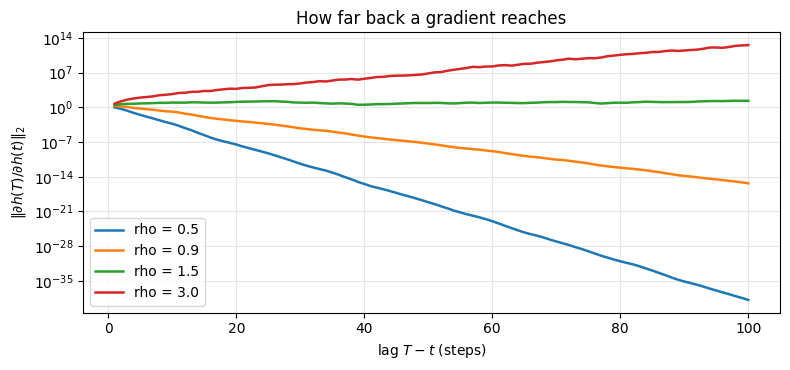

In [5]:
rome = pd.read_csv("data/elec_rome_hourly.csv", index_col="step")["load"]
time_series = rome.to_numpy()[:3000]
x_demo = (time_series[:100] - time_series.mean()) / time_series.std()

rng = np.random.default_rng(8990)
N_h = 50
W_i = rng.choice([-1.0, 1.0], size=N_h) * 0.5
W_0 = rng.normal(0, 1, (N_h, N_h))
W_0 /= np.max(np.abs(np.linalg.eigvals(W_0)))            # spectral radius 1

fig, ax = plt.subplots(figsize=(8, 3.8))
for rho in [0.5, 0.9, 1.5, 3.0]:
    W_h = rho * W_0
    h, J, norms = np.zeros(N_h), np.eye(N_h), []
    for xt in x_demo:
        h = np.tanh(W_i * xt + W_h @ h)
        J = (1 - h ** 2)[:, None] * W_h @ J               # d h(T) / d h(0), one factor per step
        norms.append(np.linalg.norm(J, 2))
    ax.plot(np.arange(1, 101), norms, lw=1.8, label=f"rho = {rho}")
ax.set(yscale="log", xlabel="lag $T - t$ (steps)", ylabel=r"$\| \partial h(T) / \partial h(t) \|_2$",
       title="How far back a gradient reaches")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

For $\rho = 0.5$ and $\rho = 0.9$, the gradient norm shrinks by a roughly constant factor per step. After 100 steps, it is about $10^{-37}$ and $10^{-15}$: an error at time $T$ carries practically no information about the state 20 or 30 steps earlier. For $\rho = 3$, the norm grows to about $10^{13}$, an exploding gradient. $\rho = 1.5$ is a borderline case: the recurrent weights stretch vectors, but many $\tanh$ units are near saturation, where their derivatives $1 - h^2$ are small, and the two effects roughly cancel. The norm then stays between about 1 and 10 over the 100 steps. Keeping a gradient alive over long lags requires this kind of balance, which is hard to maintain while the weights change during training.

The vanishing gradient makes it hard for an RNN to learn long-range dependencies: the weight updates that would link an output to an input many steps back become negligibly small, and that part of learning stalls. Exploding gradients make the weights jump or diverge. Two remedies are standard.

- **Gradient clipping** rescales the gradient whenever its norm exceeds a threshold. It stops the explosions, but does nothing against vanishing.
- **Gated units** add a second, additive path for the memory. The **Long Short-Term Memory (LSTM)** unit keeps a cell state $\mathbf{c}(t)$ updated as $\mathbf{c}(t) = \mathbf{f}(t) \odot \mathbf{c}(t-1) + \mathbf{i}(t) \odot \tilde{\mathbf{c}}(t)$, where the forget gate $\mathbf{f}(t)$ and the input gate $\mathbf{i}(t)$ are sigmoid functions of $x(t)$ and $\mathbf{h}(t-1)$, learned from the data, and $\odot$ is the element-wise product. When $\mathbf{f}(t) \approx 1$, the gradient passes through the cell state almost unchanged. The **Gated Recurrent Unit (GRU)** is a simpler variant with two gates.

A third limitation is speed. The hidden state $\mathbf{h}(t)$ cannot be computed before $\mathbf{h}(t-1)$, so the steps of a sequence must be processed one after another. RNNs therefore make poor use of the parallel hardware (GPUs) that makes other networks fast.

---

# Reservoir computing

Reservoir computing is a family of randomized RNNs, made popular in machine learning by the **Echo State Network (ESN)**. The two terms are often used interchangeably. An ESN has the same state update as the RNN above, but it differs in two ways.

<img src="media/nn/Reservoir.gif" style="width: 70%; display: block; margin: auto;">

1. The input weights $\mathbf{W}_i$ and the recurrent weights $\mathbf{W}_h$ are drawn at random and then **never trained**. The recurrent layer, with these fixed weights, is called the **reservoir**.
2. Only the output weights $\mathbf{W}_o$ are trained, and since the output is linear in the state, that is a **linear regression**. There is no BPTT, so no vanishing or exploding gradient.

The workflow has two steps.

1. **Generate the reservoir states.** Run the state update
$$\mathbf{h}(t) = \tanh\big(\mathbf{W}_i\, x(t) + \mathbf{W}_h\, \mathbf{h}(t-1)\big)$$
over the input series, $t = 1, \dots, T$, and collect the states $\mathbf{H} = \{\mathbf{h}(1), \dots, \mathbf{h}(T)\}$.
2. **Fit the readout.** Fit a regression $g(\cdot)$ from the states to the desired outputs $\mathbf{y} = \{y(1), \dots, y(T)\}$, so that $\mathbf{y} \approx g(\mathbf{H})$. In forecasting, the desired output is a future value of the input, $y(t) = x(t+\tau)$.

## The readout

The readout $g(\cdot)$ is usually a ridge regression, so it is a weight matrix $\mathbf{W}_o$ fitted by penalized least squares. The ridge penalty matters here, because the reservoir has hundreds of strongly correlated units, and plain least squares would be unstable. Any other regression model can serve as the readout, including an MLP or a tree ensemble.

<img src="media/nn/Readout.png" style="width: 50%; display: block; margin: auto;">

Fitting a model on the reservoir states is not the same as the windowed approach of Chapter 16.

- **Windowed approach.** The model predicts from the fixed amount of past information in the window,
$$x(t+\tau) = g\big(x(t-P+1), \dots, x(t-1), x(t)\big).$$
- **Reservoir approach.** The model predicts from a single reservoir state,
$$x(t+\tau) = g\big(\mathbf{h}(t)\big).$$

## Why the reservoir approach works

The reservoir extracts a large pool of dynamical features from the series and stores them in the high-dimensional state $\mathbf{h}(t)$. Unlike a fixed window, $\mathbf{h}(t)$ depends on all the past inputs back to $x(1)$. Some of these features are useful for the task, many are not, and the job of the readout is to select and combine the useful ones.

To forecast $\tau_1$ steps ahead, the readout picks one combination of reservoir features.

<img src="media/nn/Reservoir_pred1.png" style="width: 65%; display: block; margin: auto;">

To forecast at a different horizon $\tau_2$, it picks a different combination. The reservoir itself, and the pool of features it produces, stays the same.

<img src="media/nn/Reservoir_pred2.png" style="width: 65%; display: block; margin: auto;">

The reservoir is generated without **supervision**: it does not know which task it will serve. It is therefore configured to produce a pool of features that is as rich and varied as possible. In other words, the reservoir trades the lack of training for redundancy in the features it generates.

---

# Configuring the reservoir

The reservoir has a few hyperparameters. Since nothing in the reservoir is trained, there is no training that can compensate for a poor configuration, and tuning them matters more than in a trainable network.

## The spectral radius

Recent inputs should influence the current state more than old ones, so the reservoir must gradually forget its past. This is the **echo state property**, which gives the ESN its name: the state is an echo of the input history, and the effect of the initial state $\mathbf{h}(0)$, which carries no information, fades away, as does the effect of a one-off shock. In the language of dynamical systems, the reservoir must be **contractive**: two different initial states, driven by the same input, eventually converge to the same trajectory.

On the other hand, a reservoir that contracts too fast forgets everything quickly, and its features become poor. We look for a sweet spot by tuning the **spectral radius** $\rho$, the largest absolute eigenvalue of $\mathbf{W}_h$. We set it by computing the largest absolute eigenvalue $|\lambda|_\text{max}$ of a random matrix and rescaling, $\mathbf{W}_h \leftarrow \rho\, \mathbf{W}_h / |\lambda|_\text{max}$, which is what the `Reservoir` class does.

<img src="media/nn/dynamics.png" style="width: 50%; display: block; margin: auto;">

A common rule of thumb is to set $\rho$ just below 1, but good performance often requires values below or above that. To see the effect of $\rho$, we look at the **transient** of the reservoir: how long it takes to forget its initial state. We start the same reservoir from $\mathbf{h}_1(0) = [0, \dots, 0]$ and from $\mathbf{h}_2(0) = [1, \dots, 1]$, feed it a zero input so that the input does not affect the state, and track the distance $\lVert \mathbf{h}_1(t) - \mathbf{h}_2(t) \rVert_2$. If the dynamics are contractive, the distance goes to zero. If they are chaotic, it persists. Ideally, the reservoir operates near the boundary between the two, at the **edge of chaos**.

New in this chapter: the `Reservoir` class, which generates the random weights of an ESN and computes its sequence of states. We explain each piece in the sections below.

In [ ]:
class Reservoir:
    """Random recurrent layer of an echo state network.

    State update: h(t) = tanh(W_i x(t) + W_h h(t-1)), with fixed random W_i and W_h.
    """

    def __init__(self, n_units=100, spectral_radius=0.99, input_scaling=0.2,
                 connectivity=0.3, n_inputs=1, seed=0):
        rng = np.random.default_rng(seed)
        # sparse recurrent weights, nonzero entries uniform in [-0.5, 0.5]
        W_h = sparse.random(n_units, n_units, density=connectivity, random_state=rng,
                            data_rvs=lambda k: rng.uniform(-0.5, 0.5, k)).toarray()
        # rescale so that the largest absolute eigenvalue equals the spectral radius
        W_h *= spectral_radius / np.max(np.abs(np.linalg.eigvals(W_h)))
        self.W_h = W_h
        # input weights: random signs, times the input scaling
        self.W_i = rng.choice([-1.0, 1.0], size=(n_units, n_inputs)) * input_scaling
        self.n_units = n_units

    def get_states(self, x, initial_state=None):
        "States h(1), ..., h(T) for an input array x of shape (T,) or (T, n_inputs)."
        x = np.asarray(x, dtype=float).reshape(len(x), -1)
        h = np.zeros(self.n_units) if initial_state is None else np.asarray(initial_state, float)
        states = np.empty((len(x), self.n_units))
        for t in range(len(x)):
            h = np.tanh(self.W_i @ x[t] + self.W_h @ h)
            states[t] = h
        return states

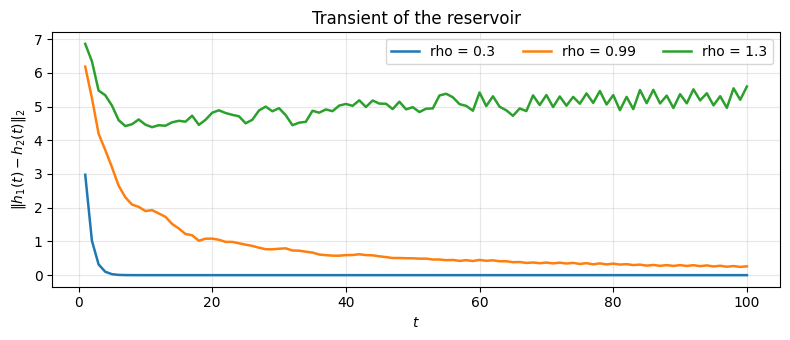

In [6]:
h0_zero, h0_one = np.zeros(100), np.ones(100)
x_zero = np.zeros(100)

fig, ax = plt.subplots(figsize=(8, 3.5))
for rho in [0.3, 0.99, 1.3]:
    res = Reservoir(n_units=100, spectral_radius=rho, seed=0)
    distance = np.linalg.norm(res.get_states(x_zero, h0_zero) - res.get_states(x_zero, h0_one), axis=1)
    ax.plot(np.arange(1, 101), distance, lw=1.8, label=f"rho = {rho}")
ax.set(title="Transient of the reservoir", xlabel="$t$",
       ylabel=r"$\| h_1(t) - h_2(t) \|_2$")
ax.legend(ncol=3); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

- With $\rho = 0.3$, the two trajectories merge within about 5 steps. The reservoir forgets very fast, so its memory is short.
- With $\rho = 0.99$, the distance falls from about 6 to below 0.5 in 50 steps, and keeps shrinking slowly. The reservoir is contractive, but it remembers for a long time.
- With $\rho = 1.3$, the distance never falls below about 4.5. The reservoir keeps the trace of its initial state, so it violates the echo state property.

A zero input is the hardest case. A real input pushes the units toward the saturated parts of the $\tanh$, which contracts the dynamics further, so the echo state property depends on the input as well as on $\rho$.

## The input scaling

The **input scaling** $\omega_\text{in}$ multiplies the input weights $\mathbf{W}_i$ and so controls how strongly the input drives the reservoir. It sets the amount of nonlinearity in the model. Near zero, $\tanh$ is almost linear, $\tanh(a) \approx a$; for large $|a|$, it saturates at $\pm 1$. A small $\omega_\text{in}$ keeps the arguments of the $\tanh$ near zero, and the reservoir behaves almost like a linear system. A large $\omega_\text{in}$ pushes the units toward saturation, and the reservoir becomes strongly nonlinear. The histograms below show the reservoir states for the standardized Rome load at three input scalings.

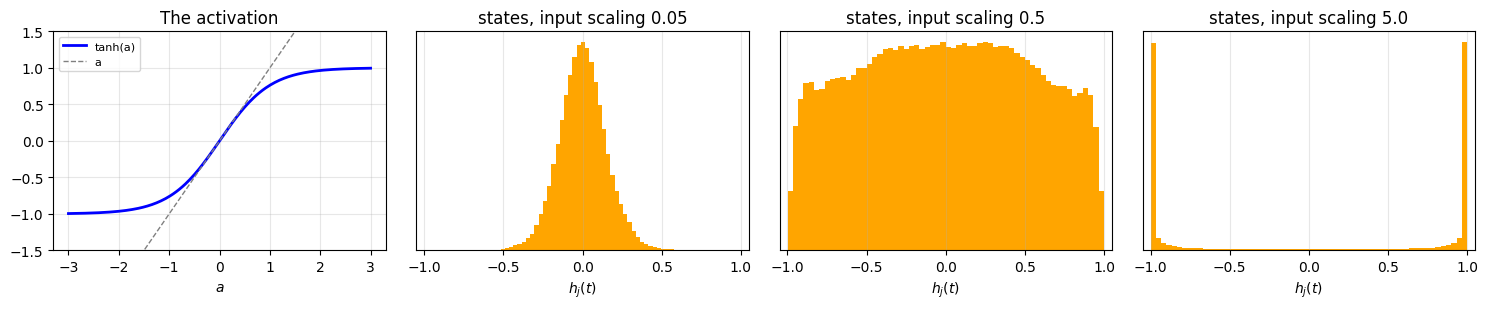

In [7]:
x_std = (time_series - time_series.mean()) / time_series.std()
a = np.linspace(-3, 3, 200)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
axes[0].plot(a, np.tanh(a), color="blue", lw=2, label="tanh(a)")
axes[0].plot(a, a, color="gray", ls="--", lw=1, label="a")
axes[0].set(ylim=(-1.5, 1.5), title="The activation", xlabel="$a$")
axes[0].legend(fontsize=8)
for ax, w in zip(axes[1:], [0.05, 0.5, 5.0]):
    S = Reservoir(n_units=300, spectral_radius=0.99, input_scaling=w, seed=0).get_states(x_std)
    ax.hist(S[100:].ravel(), bins=60, color="orange", edgecolor="none", density=True)
    ax.set(title=f"states, input scaling {w}", xlabel="$h_j(t)$", xlim=(-1.05, 1.05), yticks=())
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

- With $\omega_\text{in} = 0.05$, the states stay within about $\pm 0.5$, in the almost-linear part of the $\tanh$. The reservoir is close to a linear system, a bank of linear filters of the input.
- With $\omega_\text{in} = 0.5$, the states spread over the whole range $(-1, 1)$ and use the curved part of the $\tanh$.
- With $\omega_\text{in} = 5$, almost all states sit at $\pm 1$. The units are saturated and act like on/off switches, so the state hardly responds to the size of the input.

Like the spectral radius, $\omega_\text{in}$ should be tuned. Small values, around 0.1, are a common starting point, but the best value depends on the data, as we will see.

## The number of units and the other hyperparameters

The number of reservoir units $N_h$ matters less. A larger reservoir usually gives better forecasts, at a higher computing cost. A good starting point is $N_h = 300$, increased until the performance stops improving. Other hyperparameters, such as the **connectivity** (the fraction of nonzero entries in $\mathbf{W}_h$) and an optional noise added to the state update, are usually less critical and can stay at their default values.

---

# Forecasting the electricity load with an ESN

## The data

We use the same series as in Chapter 16: the first 3,000 hours of the Rome electricity load, the first 2,700 hours for training, and the last 300 for testing. The task is again to forecast the load $\tau = 24$ hours ahead, $y(t) = x(t+24)$, so the ESN results can be compared with the MLP results of Chapter 16 on the same 300 test hours.

We standardize the series with the mean and standard deviation of the training period, run the reservoir over the **whole** standardized series in one pass, and then split the states by time. This is legitimate: the state $\mathbf{h}(t)$ depends only on $x(1), \dots, x(t)$, so a test state contains no future information, and each test state continues from the last training state rather than from an uninformative $\mathbf{h}(0)$.

In [8]:
horizon = 24
n_train = int(0.9 * len(time_series))                  # 2,700 training hours
scaler = StandardScaler().fit(time_series[:n_train].reshape(-1, 1))
x_scaled = scaler.transform(time_series.reshape(-1, 1)).ravel()
to_load = lambda z: scaler.inverse_transform(np.asarray(z).reshape(-1, 1)).ravel()

# the state at hour t is used to forecast hour t + 24
origins = np.arange(len(time_series) - horizon)        # t = 0, ..., 2975
targets = origins + horizon
n_drop = 100                                           # washout: drop the first 100 states
train = (origins >= n_drop) & (targets < n_train)
test = targets >= n_train
print(f"training pairs: {train.sum()},  test pairs: {test.sum()}")
print(f"test targets: hours {targets[test][0]}-{targets[test][-1]}")

training pairs: 2576,  test pairs: 300
test targets: hours 2700-2999


The reservoir starts from $\mathbf{h}(0) = \mathbf{0}$, which is not informative, so we drop the first `n_drop = 100` states, the **washout** period. With the load as input, the distance between two differently initialized copies of the 900-unit reservoir used below falls from about 18 to 0.003 in 100 steps, so 100 steps are enough.

## Computing the states

We use a reservoir with $N_h = 900$ units, spectral radius $0.99$, input scaling $0.1$ and connectivity $0.25$.

In [9]:
res = Reservoir(n_units=900, spectral_radius=0.99, input_scaling=0.1, connectivity=0.25, seed=0)
start = time.perf_counter()
states = res.get_states(x_scaled[:len(origins)])
print(f"states: {states.shape} in {time.perf_counter() - start:.2f} s")

states_tr, y_tr = states[train], x_scaled[targets[train]]
states_te, y_te = states[test], time_series[targets[test]]      # test targets in load units
print("states_tr:", states_tr.shape, "  states_te:", states_te.shape)

states: (2976, 900) in 0.74 s
states_tr: (2576, 900)   states_te: (300, 900)


## A linear readout

We fit a ridge regression from the 900 state units to the standardized load 24 hours later, and use it to forecast the test period. We transform the forecasts back to load units before computing the MSE.

training time: 0.111 s
seasonal naive MSE: 22.29
ESN (ridge)    MSE: 16.17


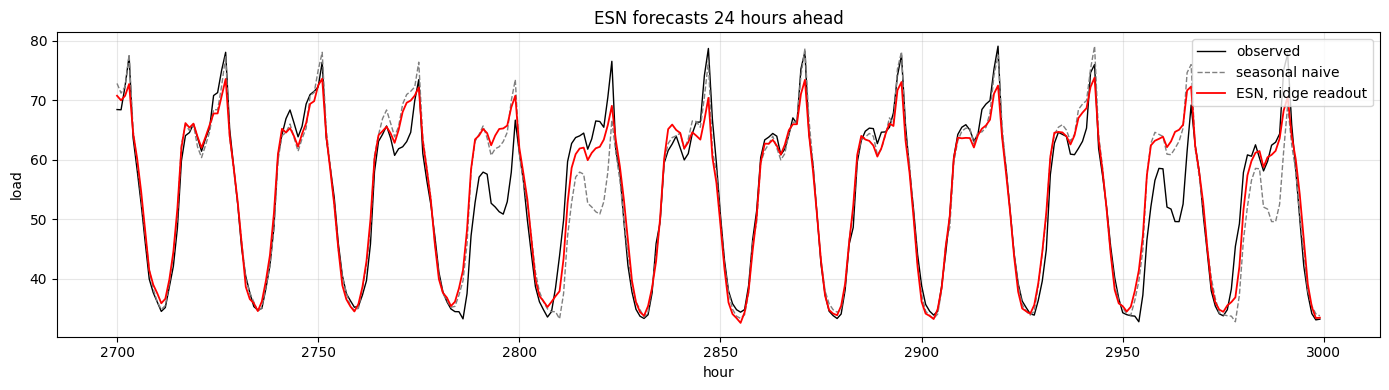

In [10]:
start = time.perf_counter()
ridge = Ridge(alpha=1.0).fit(states_tr, y_tr)
print(f"training time: {time.perf_counter() - start:.3f} s")
y_esn = to_load(ridge.predict(states_te))

y_naive = time_series[origins[test]]                            # seasonal naive: x(t)
test_hours = targets[test]
print(f"seasonal naive MSE: {mse(y_te, y_naive):.2f}")
print(f"ESN (ridge)    MSE: {mse(y_te, y_esn):.2f}")

ax = run_sequence_plot(y_te, x=test_hours, color="black", figsize=(14, 4), label="observed",
                       xlabel="hour", ylabel="load", title="ESN forecasts 24 hours ahead")
ax.plot(test_hours, y_naive, color="gray", ls="--", lw=1, label="seasonal naive")
ax.plot(test_hours, y_esn, color="red", lw=1.3, label="ESN, ridge readout")
ax.legend(); plt.tight_layout(); plt.show()

The ESN forecast (MSE 16.17) is about 27% better than the seasonal naive forecast (22.29). It is also better than every MLP of Chapter 16 with a window of 12 to 48 hours, whose best average over seeds was 18.48 (at $P = 48$). Only the linear model on a one-week window did better there (12.45). The ESN is also fast: the 2,976 states take less than a second, and the ridge readout about 0.1 s, against 2-7 s for a single MLP fit.

The plot shows where the gain comes from. Like the MLP, the ESN misses the start of the two low days, around hours 2790 and 2955. But it does not repeat them on the next day, as the seasonal naive forecast does (around hours 2815 and 2980).

The reservoir is random, so the result depends on its seed, as the MLP depended on its initial weights. We refit with five reservoir seeds.

In [11]:
seed_mse = []
for seed in range(5):
    S = Reservoir(n_units=900, spectral_radius=0.99, input_scaling=0.1, connectivity=0.25,
                  seed=seed).get_states(x_scaled[:len(origins)])
    fit = Ridge(alpha=1.0).fit(S[train], y_tr)
    seed_mse.append(mse(y_te, to_load(fit.predict(S[test]))))
print("test MSE by reservoir seed:", np.round(seed_mse, 2))
print(f"mean {np.mean(seed_mse):.2f}, range {np.min(seed_mse):.2f}-{np.max(seed_mse):.2f}")

test MSE by reservoir seed: [16.17 17.3  16.57 17.41 15.99]
mean 16.69, range 15.99-17.41


The test MSE stays between 15.99 and 17.41 for the five reservoirs, a narrower spread than for the MLP seeds of Chapter 16, and every reservoir beats the seasonal naive forecast clearly. A large random reservoir gives a similar pool of features whatever its seed, and the readout is the unique solution of a ridge regression, with no local minima.

## Tuning the reservoir on a validation period

So far, we used a fixed configuration. To tune $\rho$ and $\omega_\text{in}$ without touching the test period, we hold out the last 300 training hours (hours 2400-2699) as a **validation period**. We fit the readout on the targets before hour 2400, score each configuration on the validation targets, and refit the chosen one on the whole training period. To keep the search fast, we use reservoirs of 300 units, with three seeds per configuration.

In [12]:
n_fit = n_train - 300
fit_rows = (origins >= n_drop) & (targets < n_fit)
val_rows = (targets >= n_fit) & (targets < n_train)

rows = []
start = time.perf_counter()
for rho in [0.5, 0.9, 0.99, 1.2]:
    for w in [0.05, 0.1, 0.5, 1.0, 2.0]:
        val_mse = []
        for seed in range(3):
            S = Reservoir(n_units=300, spectral_radius=rho, input_scaling=w, connectivity=0.25,
                          seed=seed).get_states(x_scaled[:len(origins)])
            fit = Ridge(alpha=1.0).fit(S[fit_rows], x_scaled[targets[fit_rows]])
            val_mse.append(mse(time_series[targets[val_rows]], to_load(fit.predict(S[val_rows]))))
        rows.append({"rho": rho, "input scaling": w, "validation MSE": np.mean(val_mse)})
print(f"{len(rows)} configurations x 3 seeds in {time.perf_counter() - start:.0f} s")
print(f"seasonal naive on the validation period: "
      f"{mse(time_series[targets[val_rows]], time_series[origins[val_rows]]):.2f}")
grid = pd.DataFrame(rows).pivot(index="rho", columns="input scaling", values="validation MSE")
grid.round(2)

20 configurations x 3 seeds in 12 s
seasonal naive on the validation period: 47.70


input scaling,0.05,0.10,0.50,1.00,2.00
rho,,,,,
0.50,45.17,45.03,45.07,47.19,51.65
0.90,45.63,45.24,40.24,41.76,45.30
0.99,45.49,44.66,41.54,41.36,45.09
1.20,52.16,57.63,45.00,42.95,46.54


On the validation period, the best cell is $\rho = 0.9$, $\omega_\text{in} = 0.5$ (MSE 40.24), ahead of the configuration used above, $\rho = 0.99$, $\omega_\text{in} = 0.1$ (44.66).

- Moderate input scalings (0.5 and 1) do best for $\rho = 0.9$ and $0.99$, and the largest scaling (2) is worse for every $\rho$.
- $\rho = 1.2$ is worst at the small input scalings, consistent with the transient plot: without the saturation brought by a strong input, such a reservoir does not forget its past.
- All the validation MSEs are about twice the test MSEs, and they beat the seasonal naive forecast on the validation period (47.70) by a modest margin only. The validation hours contain a drop of the daily mean load from about 65-70 to about 55 around hours 2620-2640, which no configuration can forecast.

We now refit the chosen configuration with 900 units on the whole training period, with five seeds.

In [13]:
best_rho, best_w = grid.stack().idxmin()
print(f"chosen: rho = {best_rho}, input scaling = {best_w}")

tuned_mse = []
for seed in range(5):
    S = Reservoir(n_units=900, spectral_radius=best_rho, input_scaling=best_w, connectivity=0.25,
                  seed=seed).get_states(x_scaled[:len(origins)])
    fit = Ridge(alpha=1.0).fit(S[train], y_tr)
    tuned_mse.append(mse(y_te, to_load(fit.predict(S[test]))))
print("test MSE by reservoir seed:", np.round(tuned_mse, 2))
print(f"mean {np.mean(tuned_mse):.2f}, range {np.min(tuned_mse):.2f}-{np.max(tuned_mse):.2f}")

chosen: rho = 0.9, input scaling = 0.5


test MSE by reservoir seed: [23.13 23.13 22.95 23.11 24.06]
mean 23.27, range 22.95-24.06


The tuned configuration is **worse** on the test period (mean MSE 23.27) than the configuration we started with (16.69), and no better than the seasonal naive forecast (22.29). The validation period ranked the configurations mostly by how they handle one unusual level drop, and that ranking did not carry over to the test period. The grid also used 300-unit reservoirs, while the final model has 900 units.

The lesson is about validation, not about the ESN. A single 300-hour validation window is too short and too unusual to tune on: the differences between the cells of the grid, a few MSE units, are smaller than the differences between periods. A more reliable procedure is the rolling-origin evaluation of Chapter 15, which scores each configuration on several validation windows and averages the results. We go on with the first configuration, $\rho = 0.99$ and $\omega_\text{in} = 0.1$. Keep in mind, though, that we learned it is better on the test period only after looking at the test period, so its test MSE is now an optimistic estimate of its accuracy.



---

# Summary

**Recurrent neural network**: $\ \mathbf{h}(t) = \sigma\big(\mathbf{W}_i\, x(t) + \mathbf{W}_h\, \mathbf{h}(t-1) + \mathbf{b}\big)$, $\ y(t) = \mathbf{W}_o\, \mathbf{h}(t)$. The hidden state replaces the fixed window of Chapter 16 and carries a memory of the whole past, with the same weights at every step.

- **Training.** Backpropagation through time unfolds the network over the sequence. The gradient from time $T$ back to time $t$ is a product of $T - t$ Jacobians, so it vanishes or explodes exponentially with the lag, depending on the spectral radius of $\mathbf{W}_h$. Gradient clipping stops explosions; the gated LSTM and GRU units keep a memory path along which the gradient does not vanish. RNNs must process the time steps one after another.
- **Echo state network.** $\mathbf{W}_i$ and $\mathbf{W}_h$ are random and fixed (the reservoir); only the linear readout $\mathbf{W}_o$ is trained, by ridge regression, in a fraction of a second.
- **Configuration.** The spectral radius $\rho$ sets how long the reservoir remembers (the echo state property requires the transient to die out); the input scaling $\omega_\text{in}$ sets how nonlinear it is; more units help until the gain stops. Tune $\rho$ and $\omega_\text{in}$ on a validation period, with several reservoir seeds.
- **Forecasting.** On the Rome load, an ESN with 900 units and a ridge readout reached a test MSE of 16.17 (15.99-17.41 over five reservoir seeds), against 22.29 for the seasonal naive forecast and 18.48 for the best MLP average of Chapter 16, in about one second of computing. Tuning $\rho$ and $\omega_\text{in}$ on a single 300-hour validation window chose a configuration that did worse on the test period: validate on several windows.
- **PCA and other readouts.** The 900 states are highly redundant (10 components hold 98.8% of the variance). Reducing them to 75 components barely changed the ridge forecast (16.84), but it hurt a gradient-boosting readout (22.87 against 15.70) while cutting its training time sevenfold. The quantile readout gave a 90% interval that covered 86% of the test hours.